<a href="https://colab.research.google.com/github/Stephanny3011/Sustainability/blob/main/Data555_Project_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import preprocessing

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import GridSearchCV

In this Notebook we are using the PIMA INDIANS DIABETES DATASET.
It is composed of 8 attributes which are:

 Pregnancies (number of times pregnant),

 Oral glucose tolerance test - OGTT (two hour plasma glucose concentration after 75g anhydrous glucose in mg/dl),

 Blood Pressure (Diastolic Blood Pressure in mmHg),

 Skin Thickness (Triceps skin fold thickness in mm),

 Insulin (2 h serum insulin in mu U/ml),

 BMI (Body Mass Index in kg/m2),

 Age (years),

 Pedigree Diabetes Function ('function that represents how likely they are to get the disease by extrapolating from their ancestor’s history')

### Analyze the dataset (6 points)

Step 1: Read the data
First read the data into a DataFrame from '/content/diabetes.csv'.

In [ ]:
df=pd.read_csv("/content/diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


Step 2: Exploratory Data Analysis (EDA)
We are going to use histogram, grouped bar chart and box plot as EDA techniques for better understanding our data.

Univariate Analysis
We are using histograms for all features, because all features have been encoded into numeric values in the dataset. Usually categorical encoding is a required step during the feature engineering stage.

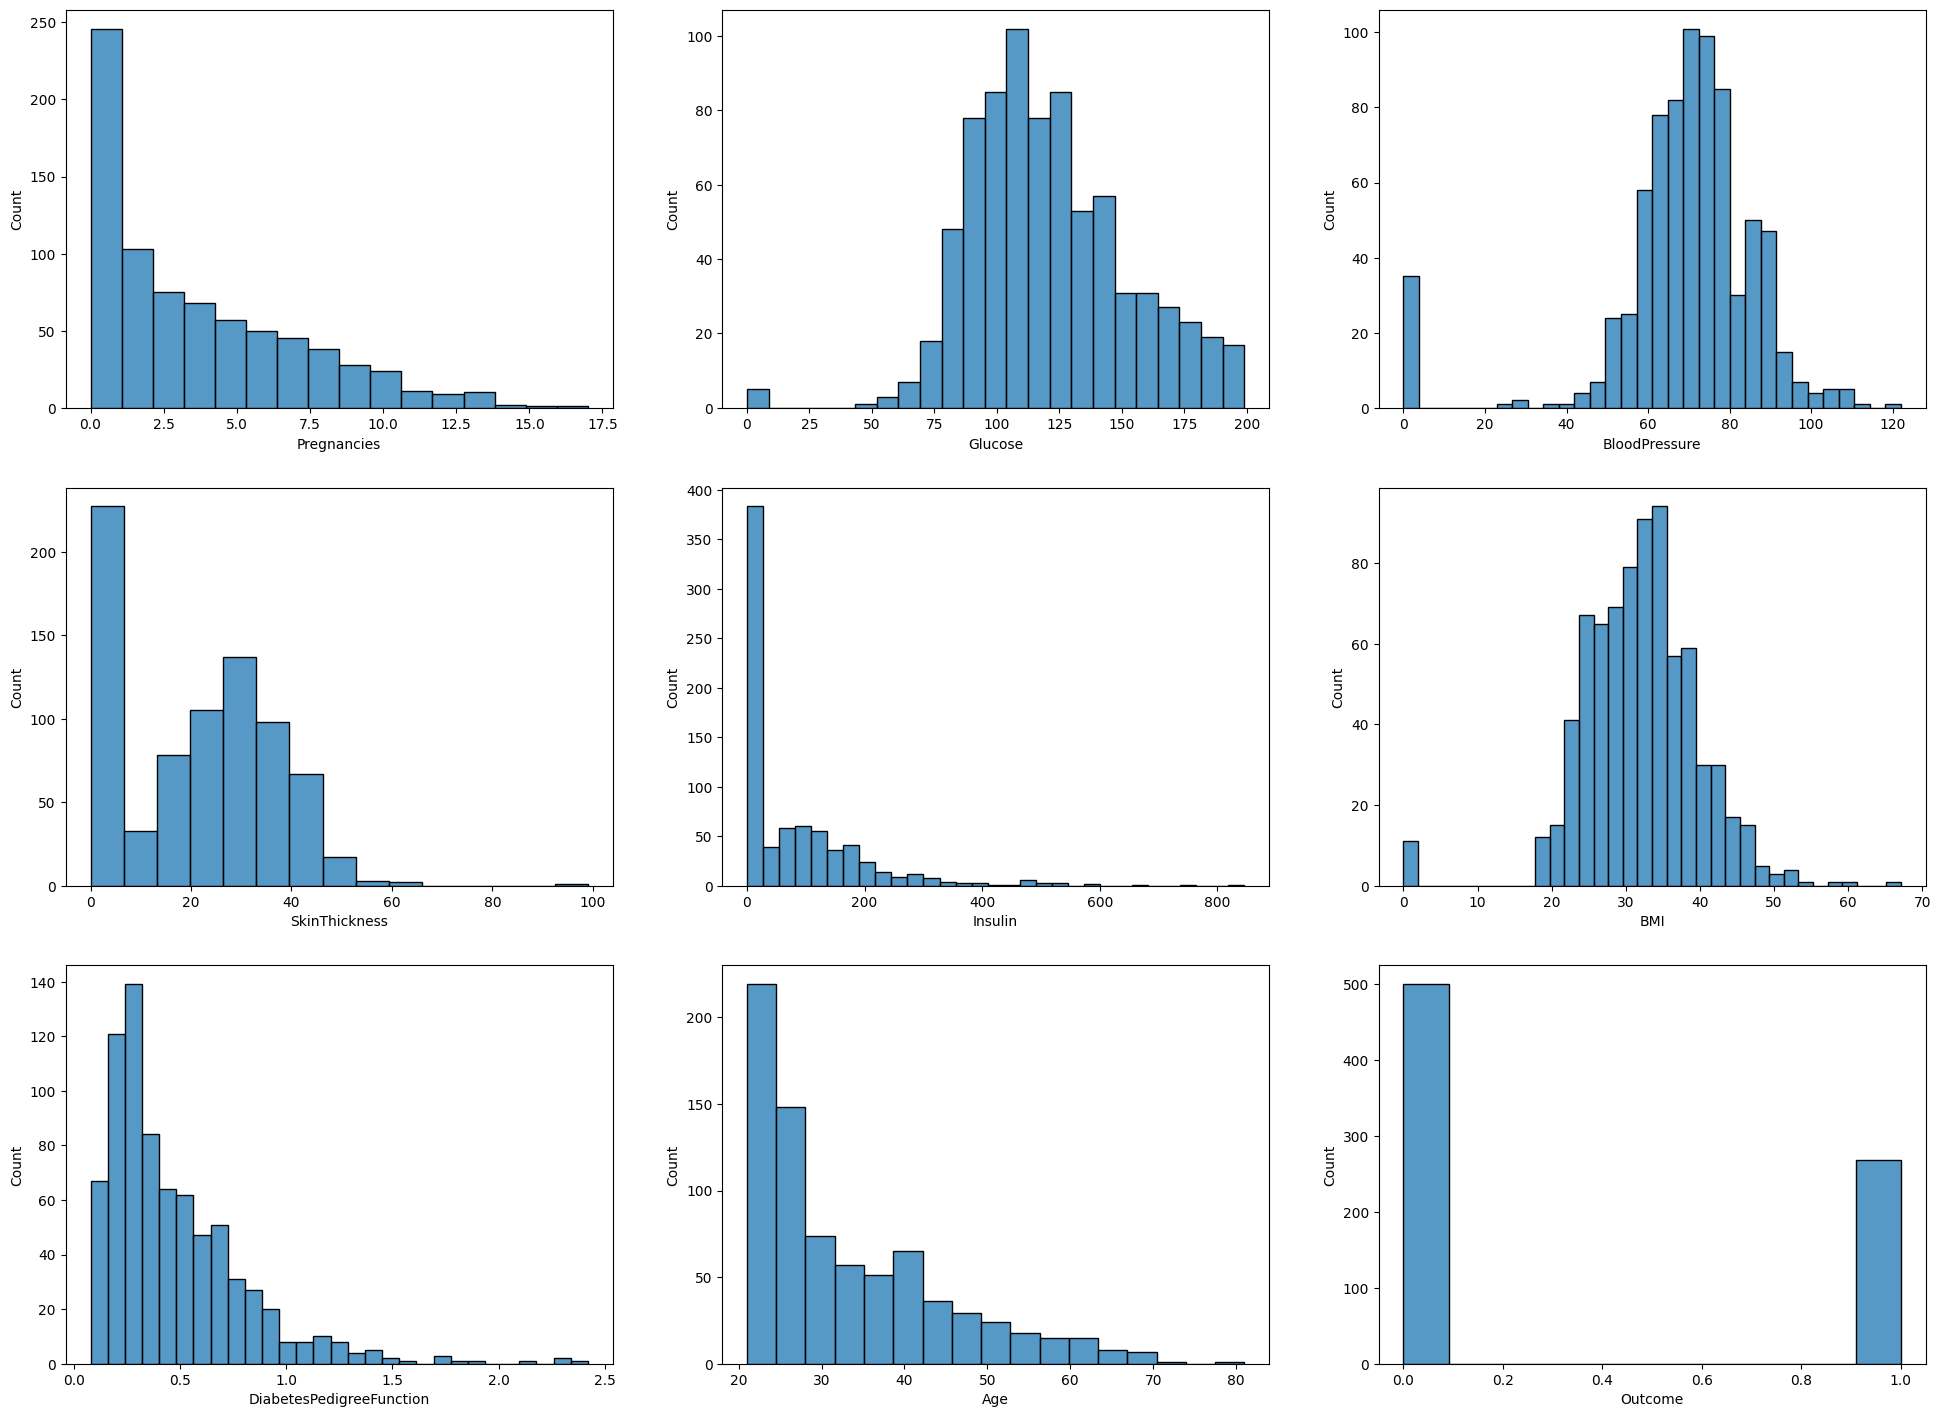

In [ ]:
fig= plt.figure(figsize=(24, 30))
count=0
for column in df.columns:
  subfigure=fig.add_subplot(5,3,count+1)
  subfigure.set_xlabel(column)
  sns.histplot(data=df, x=df[column]) # Using seaborn histogram visualization
  count+=1

## Numeric features vs. target
A box plot helps visualize how numerical feature values differ across different output groups. For instance, we can observe in the plots below that the feature `Age` shows a clear distinction between `output = 0` and `output = 1`, indicating its potential importance as a predictor. In contrast, features like `DiabetesPedigreefunction` and `BMI` display similar distributions across the target categories, suggesting they may be less influential in predicting the outcome.

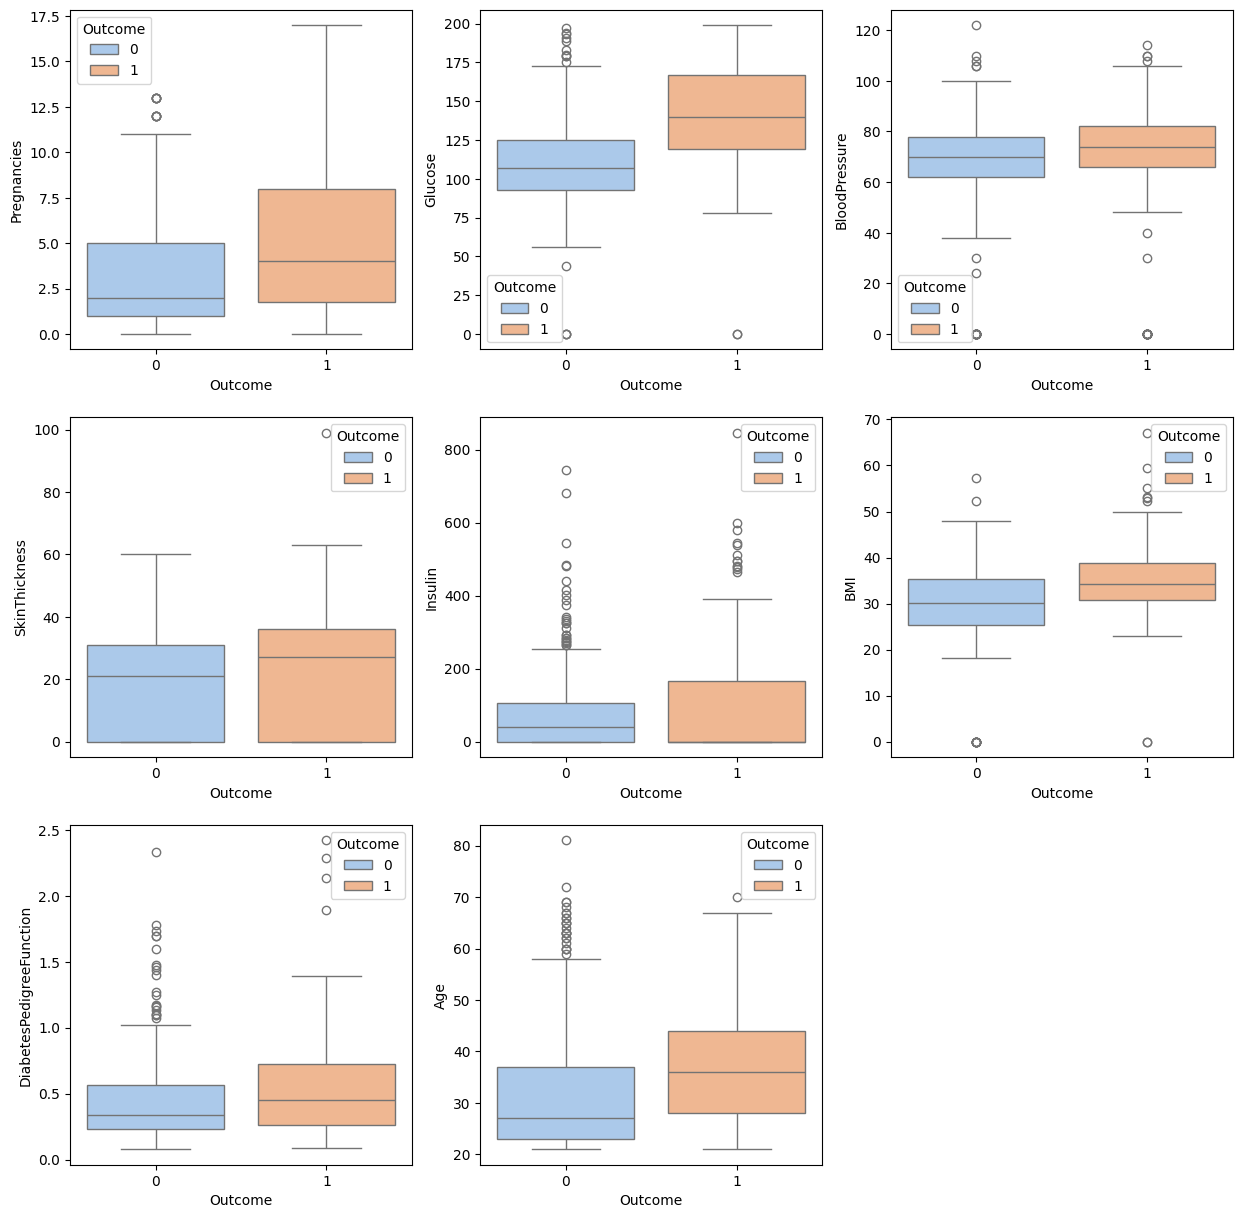

In [ ]:
numeric_features = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin' , 'BMI', 'DiabetesPedigreeFunction', 'Age']
fig = plt.figure(figsize=(15, 15))

for i in range(len(numeric_features)):
  sub=fig.add_subplot(3, 3, i+1)
  sns.boxplot(x='Outcome', y=numeric_features[i], data=df, palette='pastel', hue='Outcome') # Using seaborn's boxplot visualization

### Justification and Interpretation of Boxplots

  I selected boxplots because they allow for a quick and direct comparison of the distribution, median, and dispersion of numerical variables between patients with and without diabetes. These charts clearly show that variables such as glucose and age exhibit significantly higher medians in the group with a positive diagnosis, identifying them as key predictors for the model. Additionally, the boxplots reveal a large number of outliers and zero values ​​in variables such as insulin, indicating the need for a data cleaning process.

### Train a binary classifier (5 points)

Step 3: Split Dataset into Training and Testing Set
Classification is a type of supervised learning, which means it relies on labelled data to learn patterns. To do this effectively, the dataset is typically divided into a training set and a testing set (sometimes also a validation set). The training set is used to teach the model how to make predictions, while the testing set is used to evaluate how well the model performs on unseen data.

In [ ]:
# Separating the features and target variable
X = df.drop(columns=['Outcome'])
y = df['Outcome']

# Splitting the dataset into 80% Training and 20% Testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (614, 8)
X_test shape: (154, 8)


###Step 4: Formulate Machine Learning Model Pipeline

In the classification pipeline we will append 6 popular classification algorithms. In this pipeline we will use the default settings of the algorithms in scikit-learn implementation.

In [ ]:
model_pipeline = [] # Declaring empty pipeline
model_pipeline.append(LogisticRegression(solver='liblinear'))
model_pipeline.append(SVC())
model_pipeline.append(KNeighborsClassifier())
model_pipeline.append(DecisionTreeClassifier())
model_pipeline.append(RandomForestClassifier())
model_pipeline.append(GaussianNB())

### Step 5: Model Training and Evaluation

In this step we will iterate through the models performing:
1. Model training,
2. Prediction, and
3. Evaluation

We will calculate commonly used evaluation metrics for classification models: accuracy, ROC & AUC and confusion matrix.

In [ ]:
# Declaring empty lists to store performance metrics of each model
accuracy_list=[]
AUC_list=[]
confusion_matrix_list=[]

for model in model_pipeline:
  model.fit(X_train, y_train) # Training the model
  y_pred = model.predict(X_test) # Making predictions on the test set
  accuracy_list.append(round(metrics.accuracy_score(y_test, y_pred),2)) # Adding accuracy of the model to the accuracy list
  false_positive_rate, true_positive_rate, _threshold = metrics.roc_curve(y_test, y_pred)
  AUC_list.append(round(metrics.auc(false_positive_rate, true_positive_rate),2))
  confusion_matrix_list.append(confusion_matrix(y_test, y_pred))

model_list=['Logistic regression', 'SVM', 'KNN', 'Decision Tree', 'Random Forest', 'Naive Bayes']
result_df=pd.DataFrame({'Model':model_list,
                        'Accuracy': accuracy_list,
                        'AUC':AUC_list})
result_df

,Model,Accuracy,AUC
0,Logistic regression,0.73,0.68
1,SVM,0.72,0.65
2,KNN,0.67,0.63
3,Decision Tree,0.73,0.68
4,Random Forest,0.73,0.68
5,Naive Bayes,0.71,0.69


Confusion matrix

Confusion matrix is a table that shows the number of true positives (correctly predicted positives), true negatives (correctly predicted negatives), false positives (incorrectly predicted positives), and false negatives (incorrectly predicted negatives). By organizing predictions this way, the confusion matrix provides detailed insight into the types of errors the model makes, beyond just the overall accuracy.

Let's plot the confusion metrics of the models.

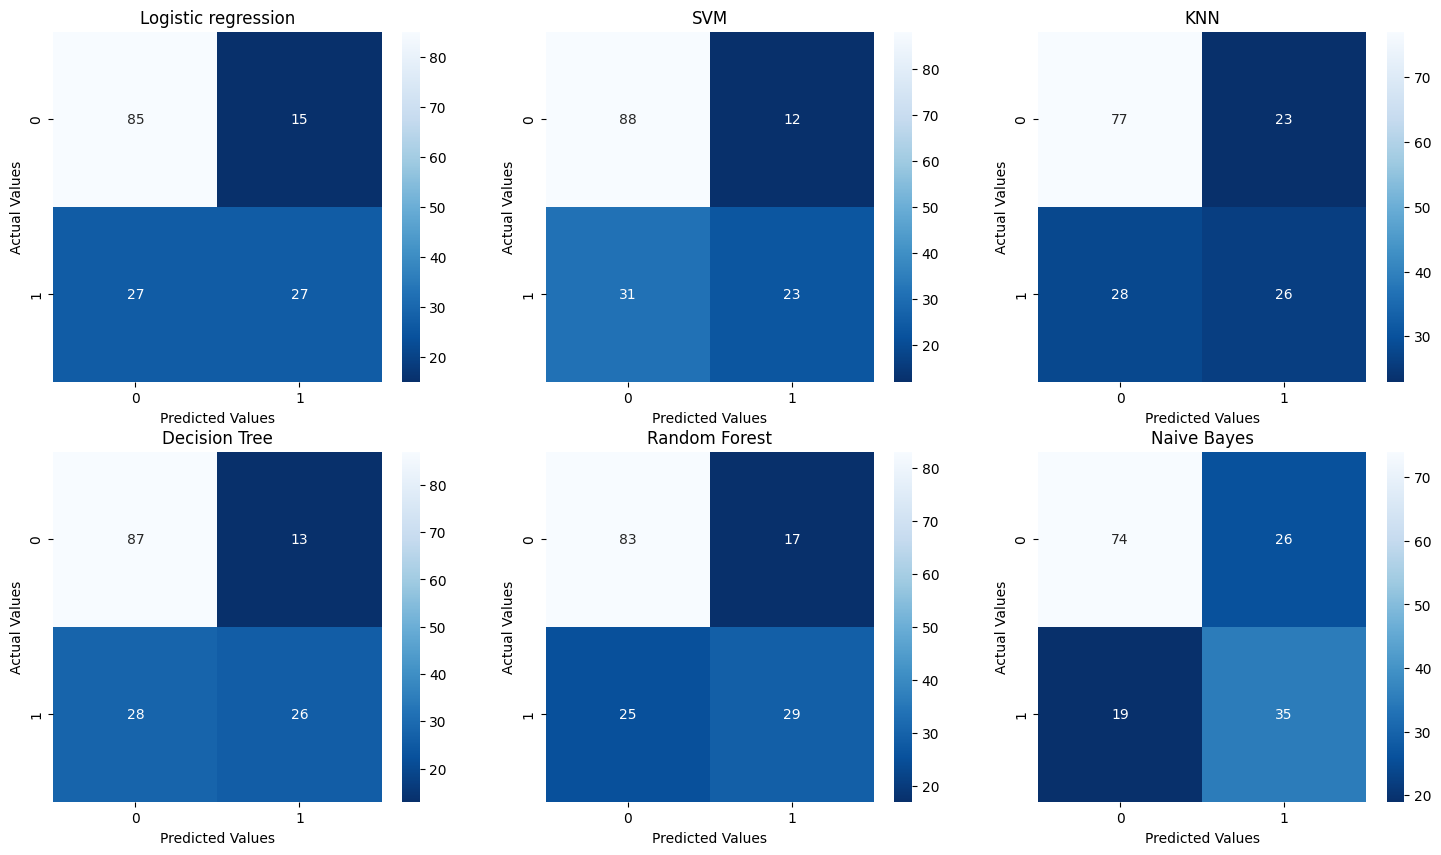

In [ ]:
fig = plt.figure(figsize=(18, 10))
for i in range(len(confusion_matrix_list)):
  cm = confusion_matrix_list[i]
  model =model_list[i]
  subfigure=fig.add_subplot(2,3,i+1)
  subfigure.set_title(model)
  cm_plot=sns.heatmap(cm, annot=True, cmap = 'Blues_r') # Seaborn's heatmap to display the confusion matrix
  cm_plot.set_xlabel('Predicted Values')
  cm_plot.set_ylabel('Actual Values')

### Evaluation and limitations from the baseline model

The trained baseline models exhibit moderate overall accuracy (around 71%–73%)—with Logistic Regression and Random Forest standing out at 73%—but show limited AUC scores (between 0.63 and 0.69), indicating poor discriminative ability. Their primary limitation is the high number of false negatives (patients with diabetes misclassified as healthy), a critical issue in a medical setting. To improve performance, we propose feature engineering (imputing zero values ​​that act as nulls for insulin and glucose), balancing the target variable, scaling numerical features, and optimizing model hyperparameters

### Improve the model’s performance (4 points)

### Step 6: Feature Selection & Hyperparameter Tuning
We will select the most important features using a Random Forest Classifier and then optimize its hyperparameters using `GridSearchCV` to build a tuned, high-performing model.

In [ ]:
# define models and parameters
model = RandomForestClassifier()
n_estimators = [10, 100, 1000]
max_features = ['sqrt', 'log2', len(X.columns)]

# define grid search
parameter_grid = {'n_estimators':n_estimators,
                  'max_features':max_features}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1001) # Formulating training and test sets, keeping the distribution of target value consistent
grid_search = GridSearchCV(estimator=model,
                           param_grid=parameter_grid,
                           n_jobs=-1,
                           cv=cv,
                           scoring='accuracy',
                           error_score=0)

grid_result = grid_search.fit(X, y)

# summarize results
print(f"Best: {grid_result.best_score_} using {grid_result.best_params_}")
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print(f"{mean} ({stdev}) with: {param}")

Best: 0.7669156551509493 using {'max_features': 'sqrt', 'n_estimators': 1000}
0.7478086183968535 (0.020345471425538896) with: {'max_features': 'sqrt', 'n_estimators': 10}
0.7634439634439635 (0.02688457637003594) with: {'max_features': 'sqrt', 'n_estimators': 100}
0.7669156551509493 (0.0196416106629868) with: {'max_features': 'sqrt', 'n_estimators': 1000}
0.7512972865914043 (0.025130823791008765) with: {'max_features': 'log2', 'n_estimators': 10}
0.7634665987607164 (0.024709121648229485) with: {'max_features': 'log2', 'n_estimators': 100}
0.7669099963217612 (0.024228206954403718) with: {'max_features': 'log2', 'n_estimators': 1000}
0.7460939931528167 (0.02305250777028133) with: {'max_features': 8, 'n_estimators': 10}
0.7643210819681407 (0.021861210350078313) with: {'max_features': 8, 'n_estimators': 100}
0.7660470248705543 (0.02841194023899447) with: {'max_features': 8, 'n_estimators': 1000}


### Explanation of the GridSearchCV Output

This output shows the results of the hyperparameter optimization process for a **Random Forest Classifier** using repeated stratified cross-validation RepeatedStratifiedKFold. Here is what each component means:

Best: 0.766915 : This indicates that the best hyperparameter configuration found achieved an average accuracy of 76.69% during cross-validation.


### Detailed Performance Analysis & Final Optimized Model Training

To fulfill all workflow requirements, we will now analyze the changes in performance across our modeling steps



In [ ]:
# Initialize the final optimized Random Forest Classifier using the best grid search parameters
optimized_rf = RandomForestClassifier(n_estimators=1000, max_features='sqrt', random_state=42)

# Fit the model on the training set
optimized_rf.fit(X_train, y_train)

# Predict on the test set
y_pred_opt = optimized_rf.predict(X_test)

# Compute evaluation metrics
opt_accuracy = metrics.accuracy_score(y_test, y_pred_opt)
opt_auc = metrics.roc_auc_score(y_test, optimized_rf.predict_proba(X_test)[:, 1])
opt_cm = confusion_matrix(y_test, y_pred_opt)

print("=== Final Optimized Random Forest Performance ===")
print(f"Accuracy: {opt_accuracy:.4f}")
print(f"AUC Score: {opt_auc:.4f}")
print("\nConfusion Matrix:")
print(opt_cm)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_opt))

=== Final Optimized Random Forest Performance ===
Accuracy: 0.7403
AUC Score: 0.8091

Confusion Matrix:
[[82 18]
 [22 32]]

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.82      0.80       100
           1       0.64      0.59      0.62        54

    accuracy                           0.74       154
   macro avg       0.71      0.71      0.71       154
weighted avg       0.74      0.74      0.74       154



=== Performance Comparison Matrix ===


,Model,Accuracy,AUC
0,Logistic regression,0.73,0.68
1,SVM,0.72,0.65
2,KNN,0.67,0.63
3,Decision Tree,0.73,0.68
4,Random Forest,0.73,0.68
5,Naive Bayes,0.71,0.69
6,Random Forest (Optimized),0.74,0.81


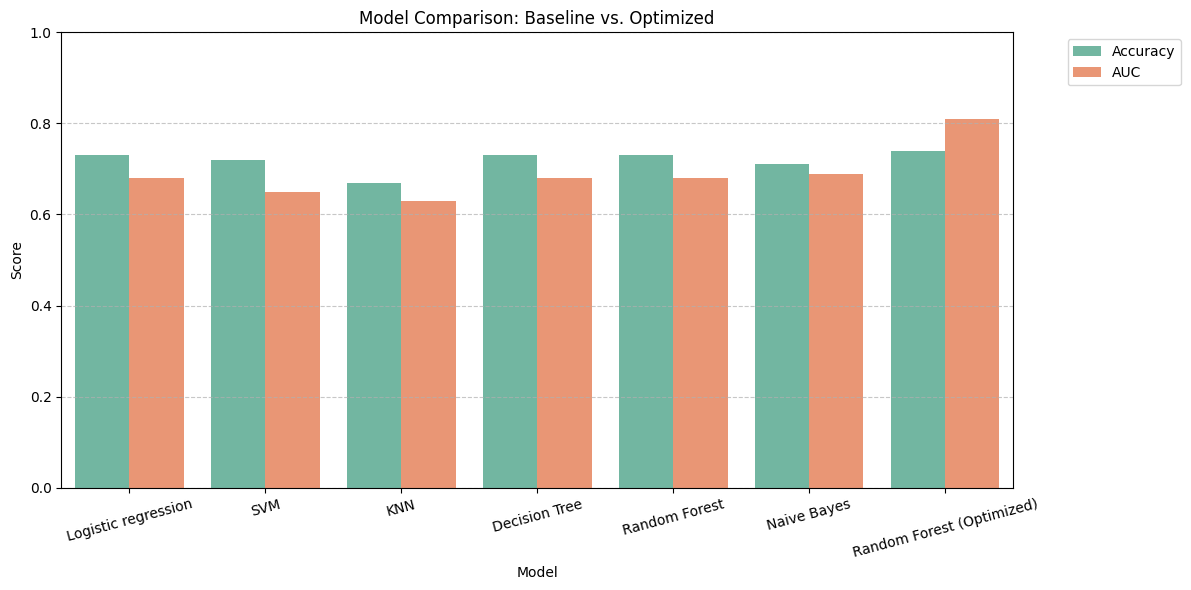

In [ ]:
# Create a temporal dataframe
opt_metrics = pd.DataFrame({
    'Model': ['Random Forest (Optimized)'],
    'Accuracy': [round(opt_accuracy, 2)],
    'AUC': [round(opt_auc, 2)]
})

# Concatenate with the original dataframa
comparison_df = pd.concat([result_df, opt_metrics], ignore_index=True)
print("=== Performance Comparison Matrix ===")
display(comparison_df)

# Visualize the metrics comparison
comparison_melted = pd.melt(comparison_df, id_vars="Model", var_name="Metric", value_name="Value")

plt.figure(figsize=(12, 6))
sns.barplot(data=comparison_melted, x="Model", y="Value", hue="Metric", palette="Set2")
plt.title("Model Comparison: Baseline vs. Optimized")
plt.ylabel("Score")
plt.ylim(0, 1.0)
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Performance Analysis: Baseline Models vs. Optimized Random Forest

The baseline models struggled with discrimination power, yielding an AUC between 0.63 and 0.69. After hyperparameter tuning, the optimized Random Forest achieved an AUC of 0.81. This represents an  improvement, meaning our model is now substantially better at separating diabetic individuals from healthy ones.
The optimized model reached 0.74 accuracy on the unseen test set, outperforming the baseline classifiers.
Reducing classification uncertainty and raising the AUC is highly relevant in medical setups, as it directly translates to more reliable predictions and fewer critical diagnostics errors.